# epx

> Epub explorer SDK for python & CLI

In [ ]:
#| default_exp epx

In [ ]:
#| export
import os, re, sys, zipfile, html2text
from lxml import etree
from pathlib import Path, PurePosixPath
from PIL import Image
from io import BytesIO
from fastcore.script import call_parse
from fastcore.basics import *

In [ ]:
#| export
def _find_epub(epub=None):
    "List of possible ways to find an EPUB file by priority: explicit path > EPX_BOOK env var > single .epub in cwd > error."
    if epub: return epub
    env = os.environ.get('EPX_BOOK')
    if env: return env
    epubs = list(Path('.').glob('*.epub'))
    if len(epubs) == 1: return str(epubs[0])
    if epubs: raise Exception(f"Multiple .epub files found: {', '.join(str(e) for e in epubs)}. Specify one.")
    raise Exception("No .epub found. Pass a path, set EPX_BOOK, or have exactly one .epub in current dir.")

In [ ]:
_find_epub()

'how-to-read-a-book.epub'

In [ ]:
!ls ..

_proc                   LICENSE                 pyproject.toml
epub_explorer           MANIFEST.in             README.md
epub_explorer.egg-info  matthews-tuttle.epub
how-to-read-a-book.epub nbs


let's symlink the book into the current nb folder

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Use a relative symlink from the notebook folder to the epub in `..`:

```bash
ln -s ../how-to-read-a-book.epub .
```

Then check it with:

```bash
ls -l *.epub
```

In [ ]:
#| export
class Epx:
    "EPUB Explorer - navigate epub files directly from ZIP."

In [ ]:
@patch
def __init__(self:Epx, path: str = None):
    self.path = Path(_find_epub(path))
    self.z = zipfile.ZipFile(self.path)
    self._h = html2text.HTML2Text()
    self._h.body_width = 0

Let's create an instance and explore the epub's internal structure:

In [ ]:
b = Epx()
b = Epx('../matthews-tuttle.epub')
b.z.namelist()[:10]

['mimetype',
 'OEBPS/Images/312d.jpg',
 'OEBPS/Images/121d.jpg',
 'OEBPS/Images/158b.jpg',
 'OEBPS/Images/215d.jpg',
 'OEBPS/Images/tx68.jpg',
 'OEBPS/Images/302d.jpg',
 'OEBPS/Images/t770a.jpg',
 'OEBPS/Images/145c.jpg',
 'OEBPS/Images/trs.jpg']

Every epub starts with `META-INF/container.xml`, which points to the main package file (OPF):

In [ ]:
c = etree.fromstring(b.z.read('META-INF/container.xml'))
etree.indent(c)
print(etree.tostring(c, pretty_print=True).decode())

<container xmlns="urn:oasis:names:tc:opendocument:xmlns:container" version="1.0">
  <rootfiles>
    <rootfile full-path="OEBPS/content.opf" media-type="application/oebps-package+xml"/>
  </rootfiles>
</container>



In [ ]:
ns = {'c': 'urn:oasis:names:tc:opendocument:xmlns:container'}
opf_path = c.find('.//c:rootfile', ns).get('full-path')
opf_dir = str(Path(opf_path).parent)
opf_path, opf_dir

('OEBPS/content.opf', 'OEBPS')

The OPF is the epub's central manifest — it has metadata (title, authors), a file manifest, and a spine (reading order):

In [ ]:
opf = etree.fromstring(b.z.read(opf_path))
opf_ns = {'opf': 'http://www.idpf.org/2007/opf', 'dc': 'http://purl.org/dc/elements/1.1/'}
meta = opf.find('opf:metadata', opf_ns)
meta

<Element {http://www.idpf.org/2007/opf}metadata at 0x111db4ec0>

`opf_ns` maps shorthand prefixes to the XML namespace URIs defined by the EPUB spec — `'opf'` for the package format, `'dc'` for Dublin Core metadata. These URIs are fixed by the standard (they're identifiers, not web addresses). `findtext('dc:title', '', opf_ns)` uses XPath to find the first `<title>` element in the Dublin Core namespace and return its text, defaulting to `''` if missing.

In [ ]:
# epub title
meta.findtext('dc:title', '', opf_ns) 

'Tuttle Learning Chinese Characters'

In [ ]:
# list of authors
[e.text for e in meta.findall('dc:creator', opf_ns)]

['Alison Matthews', 'Laurence Matthews']

In [ ]:
manifest = {
    item.get('id'): {'href': item.get('href'), 'media-type': item.get('media-type')}
    for item in opf.findall('.//opf:manifest/opf:item', opf_ns)
}
list(manifest.items())[:3]

[('ncx', {'href': 'toc.ncx', 'media-type': 'application/x-dtbncx+xml'}),
 ('simkai.ttf',
  {'href': 'Fonts/simkai.ttf', 'media-type': 'application/x-font-ttf'}),
 ('times.ttf',
  {'href': 'Fonts/times.ttf', 'media-type': 'application/x-font-ttf'})]

In [ ]:
spine_ids = [ref.get('idref') for ref in opf.findall('.//opf:spine/opf:itemref', opf_ns)]
spine_ids[:5]

['Cover.xhtml',
 'Dedication.xhtml',
 'Copyright.xhtml',
 'TitlePage.xhtml',
 'Contents.xhtml']

Now we can wrap all of that into `_load_opf`, which does everything we just explored — finds the OPF via `container.xml`, then extracts metadata, manifest, and spine:

In [ ]:
#| export
@patch
def _load_opf(self: Epx):
    "Parse container.xml to find OPF, then extract metadata, manifest, and spine."
    container = etree.fromstring(self.z.read('META-INF/container.xml'))
    ns = {'c': 'urn:oasis:names:tc:opendocument:xmlns:container'}
    self.opf_path = container.find('.//c:rootfile', ns).get('full-path')
    self.opf_dir = PurePosixPath(self.opf_path).parent
    
    opf = etree.fromstring(self.z.read(self.opf_path))
    opf_ns = {'opf': 'http://www.idpf.org/2007/opf', 'dc': 'http://purl.org/dc/elements/1.1/'}
    
    meta = opf.find('opf:metadata', opf_ns)
    self.title = meta.findtext('dc:title', '', opf_ns)
    self.creators = [e.text for e in meta.findall('dc:creator', opf_ns)]
    
    self.manifest = {
        item.get('id'): {'href': item.get('href'), 'media-type': item.get('media-type')}
        for item in opf.findall('.//opf:manifest/opf:item', opf_ns)
    }
    
    self.spine_ids = [ref.get('idref') 
                      for ref in opf.findall('.//opf:spine/opf:itemref', opf_ns)]

In [ ]:
b._load_opf()
list(b.manifest.values())[:3]

[{'href': 'toc.ncx', 'media-type': 'application/x-dtbncx+xml'},
 {'href': 'Fonts/simkai.ttf', 'media-type': 'application/x-font-ttf'},
 {'href': 'Fonts/times.ttf', 'media-type': 'application/x-font-ttf'}]

The NCX file maps file paths to human-readable chapter names. `_load_toc` finds it in the manifest, and `_parse_nav` walks its `navPoint` tree recursively (since TOCs can be nested):

Zip entries are matched by exact name so we often find `toc.ncx` instead of `./toc.ncx`. We create the little helper `_zp` below to solve that when we do `Path(self.opf_dir) / ncx_item['href']` for example

In [ ]:
ncx_item = first((v for v in b.manifest.values() 
                    if v['media-type'] == 'application/x-dtbncx+xml'))
p = str(Path(b.opf_dir) / ncx_item['href'])
p

'OEBPS/toc.ncx'

In [ ]:
#| export
def _zp(*parts): 
    "Join EPUB internal paths as normalized POSIX strings."
    return str(PurePosixPath(*parts))


@patch
def _zip_read(self:Epx, href): return self.z.read(_zp(self.opf_dir, href))

In [ ]:
#| export
@patch
def _load_toc(self: Epx):
    "Parse NCX table of contents into a href→label mapping."
    ncx_item = next((v for v in self.manifest.values() 
                     if v['media-type'] == 'application/x-dtbncx+xml'), None)
    self._toc_labels = {}
    if not ncx_item: return
    ncx = etree.fromstring(self._zip_read(ncx_item['href']))
    ncx_ns = {'n': 'http://www.daisy.org/z3986/2005/ncx/'}
    self._parse_nav(ncx.find('n:navMap', ncx_ns), ncx_ns)

In [ ]:
#| export
@patch
def _parse_nav(self: Epx, parent, ns):
    "Recursively walk navPoint elements, storing first label per href."
    for np in parent.findall('n:navPoint', ns):
        label = np.findtext('n:navLabel/n:text', '', ns)
        src = np.find('n:content', ns).get('src').split('#')[0]
        if src not in self._toc_labels: self._toc_labels[src] = label
        self._parse_nav(np, ns)

In [ ]:
b._load_toc()
list(b._toc_labels.items())[:5]

[('Text/Cover.xhtml', 'Cover'),
 ('Text/Dedication.xhtml', 'Dedication'),
 ('Text/Copyright.xhtml', 'Copyright'),
 ('Text/Contents.xhtml', 'Contents'),
 ('Text/Acknowledgments.xhtml', 'Acknowledgments')]

Now we can update `__init__` to call both loading methods automatically:

In [ ]:
#| export
@patch
def __init__(self: Epx, path: str = None):
    self.path = Path(_find_epub(path))
    self.z = zipfile.ZipFile(self.path)
    self._h = html2text.HTML2Text()
    self._h.body_width = 0
    self._load_opf()
    self._load_toc()

In [ ]:
b = Epx()
b.title, b.creators, len(b.spine_ids)

('How to Read a Book: The Classic Guide to Intelligent Reading (A Touchstone Book)',
 ['Charles Van Doren', 'Mortimer J. Adler'],
 36)

Epub content is XHTML. `_read_xhtml` reads a file from the ZIP, converts to markdown via `html2text`, then cleans up relative image paths and empty headings:

In [ ]:
#| export
@patch
def _href(self: Epx, idx):
    "Look up the content file path for spine index `idx`."
    return self.manifest[self.spine_ids[idx]]['href']

@patch
def _read_xhtml(self: Epx, href):
    "Read XHTML from ZIP by `href` and convert to clean markdown."
    raw = self._zip_read(href).decode()
    md = self._h.handle(raw).strip()
    md = re.sub(r'!\[([^\]]*)\]\(\.\./([^)]+)\)', r'![\1](\2)', md)  # fix relative image paths
    md = re.sub(r'^#+\s*$', '', md, flags=re.MULTILINE)               # remove empty headings
    return md.strip()

### Public API

`toc` lists all spine items with their TOC labels, `section` reads one by index, and `img` extracts embedded images:

In [ ]:
#| export
@patch
def toc(self: Epx) -> str:
    "List all spine items with their TOC labels, indexed for `section()`."
    lines = ['section  name']
    for i, sid in enumerate(self.spine_ids):
        href = self.manifest[sid]['href']
        label = self._toc_labels.get(href, href)
        lines.append(f"{i:>7}  {label}")
    return '\n'.join(lines)

In [ ]:
b = Epx()
print(b.toc())

section  name
      0  titlepage.xhtml
      1  Cover
      2  text/part0001.html
      3  text/part0002.html
      4  text/part0003.html
      5  Preface
      6  Part One: The Dimensions of Reading
      7  Chapter 1: The Activity and Art of Reading
      8  Chapter 2: The Levels of Reading
      9  Chapter 3: The First Level of Reading: Elementary Reading
     10  Chapter 4: The Second Level of Reading: Inspectional Reading
     11  Chapter 5: How to Be a Demanding Reader
     12  Part Two: The Third Level of Reading: Analytical Reading
     13  Chapter 6: Pigeonholing a Book
     14  Chapter 7: X-raying a Book
     15  Chapter 8: Coming to Terms with an Author
     16  Chapter 9: Determining an Author’s Message
     17  Chapter 10: Criticizing a Book Fairly
     18  Chapter 11: Agreeing or Disagreeing with an Author
     19  Chapter 12: Aids to Reading
     20  Part Three: Approaches to Different Kinds of Reading Matter
     21  Chapter 13: How to Read Practical Books
     22  Chap

In [ ]:
#| export
@patch
def _href(self: Epx, idx):
    "Look up the content file path for spine index `idx`."
    return self.manifest[self.spine_ids[idx]]['href']

@patch
def _read_xhtml(self: Epx, href):
    "Read XHTML from ZIP by `href` and convert to clean markdown."
    raw = self._zip_read(href).decode()
    md = self._h.handle(raw).strip()
    md = re.sub(r'!\[([^\]]*)\]\(\.\./([^)]+)\)', r'![\1](\2)', md)  # fix relative image paths
    md = re.sub(r'^#+\s*$', '', md, flags=re.MULTILINE)               # remove empty headings
    return md.strip()

In [ ]:
#| export
@patch
def __repr__(self: Epx):
    return f"{self.title} by {', '.join(self.creators)} ({len(self.spine_ids)} sections)"

In [ ]:
b

How to Read a Book: The Classic Guide to Intelligent Reading (A Touchstone Book) by Charles Van Doren, Mortimer J. Adler (36 sections)

In [ ]:
b.images()

AttributeError: 'Epx' object has no attribute 'images'

In [ ]:
#| export
@patch
def section(self: Epx, idx: int) -> str:
    "Read spine section `idx` and return as markdown."
    return self._read_xhtml(self._href(idx))

In [ ]:
print(b.section(5)[:200])

## PREFACE

How to Read a Book was first published in the early months of 1940. To my surprise and, I confess, to my delight, it immediately became a best seller and remained at the top of the nationw


In [ ]:
#| export
@patch
def images(self:Epx) -> list[str]:
    "List image hrefs available in the book (OPF-relative paths for `img()`)."
    return [v['href'] for v in self.manifest.values()
            if (v.get('media-type') or '').startswith('image/')]

In [ ]:
b.images()

['images/00001.jpeg', 'images/00002.jpeg']

In [ ]:
#| export
@patch
def img(self: Epx, path: str) -> Image.Image:
    "Extract image by OPF-relative href (use one of `images()`)."
    return Image.open(BytesIO(self._zip_read(path)))

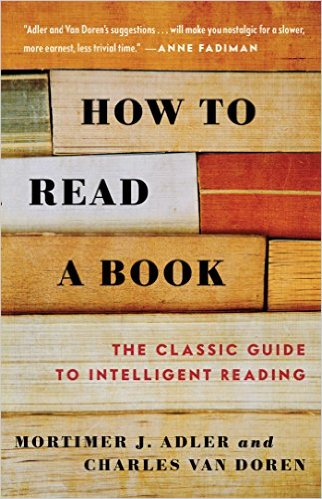

In [ ]:
b.img('images/00001.jpeg')


### Usage

`Epx` reads epub files directly from ZIP, with no extraction needed. It auto-discovers a single `.epub` in the current directory:

### Table of contents

`toc()` maps spine indices to their TOC labels — these indices are what you pass to `read`:

In [ ]:
b = Epx()
print(b.toc()[:300])

section  name
      0  titlepage.xhtml
      1  Cover
      2  text/part0001.html
      3  text/part0002.html
      4  text/part0003.html
      5  Preface
      6  Part One: The Dimensions of Reading
      7  Chapter 1: The Activity and Art of Reading
      8  Chapter 2: The Levels of Reading
      


### Reading a section

`section` converts any spine section to markdown:

In [ ]:
print(b.section(5)[:100])

### Images

Images can be extracted by their epub-internal path (as shown in markdown image links from `read`):

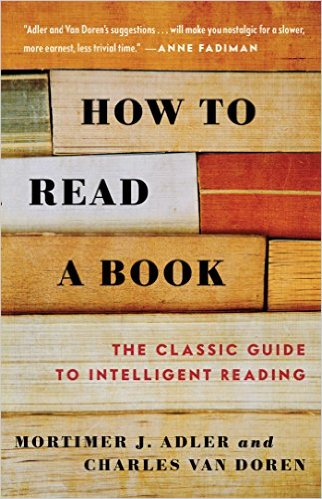

In [ ]:
b.img('images/00001.jpeg')


### CLI

`@call_parse` exposes the same functionality from the command line:

In [ ]:
#| export
@call_parse
def epx(section: int = None, epub: str = None):
    "EPUB Explorer - navigate epub files with Unix-friendly output."
    book = Epx(epub)
    if section is not None: print(book.section(section))
    else: print(book.toc())

In [ ]:
%%bash
cd .. && pip install -e .

Obtaining file:///Users/pengren/go/github.com/AnswerDotAI/epub-explorer


  Installing build dependencies: started


  Installing build dependencies: finished with status 'done'


  Checking if build backend supports build_editable: started


  Checking if build backend supports build_editable: finished with status 'done'


...

    Uninstalling epub-explorer-0.0.1:


      Successfully uninstalled epub-explorer-0.0.1



[notice] A new release of pip is available: 2

5.3 -> 26.0.1
[notice] To upda

te, run: pip3 install --upgrade pip


In [ ]:
%%bash
python ../epub_explorer/epx.py

section  name
      0  titlepage.xhtml
      1  Cover
      2  text/part0001.html
      3  text/part

0002.html
      4  text/part0003.html
      5  Preface
      6  Part One: The Dimensions of Reading


      7  Chapter 1: The Activity and Art of Reading
      8  Chapter 2: The Levels of Reading
      

9  Chapter 3: The First Level of Reading: Elementary Reading
     10  Chapter 4: The Second Level of

 Reading: Inspectional Reading
     11  Chapter 5: How to Be a Demanding Reader
     12  Part Two: T

...

d Mathematics
     26  Chapter 18: How to Read Philosophy
     27  Chapter 19: Ho w to Read Social S

cience
     28  Part Four: The Ultimate Goals of Reading
     29  Chapter 20: The Fourth Level of Re

ading: Syntopical Reading
     30  Chapter 21: Reading and the Growth of the Mind
     31  Appendix 

A: A Recommended Reading List
     32  Appendix B: Exercises and Tests at the Four Levels of Reading


     33  Index
     34  text/part0033.html
     35  Copyright


In [ ]:
%%bash
python ../epub_explorer/epx.py --section 6

# PART ONE

# The Dimensions of Reading


## Pyskills



<!-- WARNING: THIS FILE WAS AUTOGENERATED! DO NOT EDIT! -->

pyskills is a plugin system that lets Python packages register “skills”
(units of LLM-usable functionality) via standard [entry
points](https://packaging.python.org/en/latest/specifications/entry-points/).
An LLM host (e.g. solveit) discovers available pyskills without
importing them, reads lightweight descriptions via AST inspection, and
selectively loads chosen pyskills into context using standard imports.

It includes
[`list_pyskills()`](https://AnswerDotAI.github.io/pyskills/core.html#list_pyskills)
for discovery,
[`doc()`](https://AnswerDotAI.github.io/pyskills/core.html#doc) for
rendering module/class/function documentation in LLM-friendly format,
and an
[`allow()`](https://AnswerDotAI.github.io/pyskills/core.html#allow)
system for registering safe callable access in sandboxed environments.
Skills can be installed as regular packages with entry points, or
dropped into an XDG data directory for quick local use.

pyskills shares the progressive disclosure philosophy of the [Agent
Skills](https://agentskills.io/specification) specification: both
separate lightweight discovery metadata from full instructions loaded on
demand. However, where Agent Skills uses a file-system convention
(`SKILL.md` with YAML frontmatter, `scripts/`, `references/`
directories), pyskills takes a Python-native approach: pyskills are
regular Python modules discovered via standard entry points, documented
with docstrings, and loaded with `import`. This means pyskills are
directly executable, come with auto-generated structured documentation
via [`doc()`](https://AnswerDotAI.github.io/pyskills/core.html#doc), and
include a sandboxing layer via
[`allow()`](https://AnswerDotAI.github.io/pyskills/core.html#allow) for
safe execution. This makes pyskills a superset that covers discovery,
documentation, execution, and security in one system.

## Usage

### Installation

Install the latest from [pypi](https://pypi.org/project/pyskills/)

``` sh
$ pip install pyskills
```

### How to use

``` python
from pyskills import *
```

Discover what pyskills are available. This works without importing any
pyskill modules:

``` python
list_pyskills()
```

    {'pyskills.skill': 'Pyskills is a plugin system allowing Python packages to register "skills" — units of LLM-usable functionality — via standard Python entry points. An LLM host (e.g. solveit) discovers available pyskills without importing them, reads lightweight descriptions via AST inspection, and selectively loads chosen pyskills into context using standard imports.',
     'test.skill': 'A test pyskill.'}

### The [`doc`](https://AnswerDotAI.github.io/pyskills/core.html#doc) function

Once you’ve found a pyskill you want to use, import its module using
standard python syntax:

``` python
import pyskills.skill
```

Use [`doc()`](https://AnswerDotAI.github.io/pyskills/core.html#doc) to
read its full documentation.
[`doc()`](https://AnswerDotAI.github.io/pyskills/core.html#doc) works on
modules, classes, and functions, rendering LLM-friendly output in each
case.

For a **module**,
[`doc`](https://AnswerDotAI.github.io/pyskills/core.html#doc) shows all
public classes and functions with their signatures and first docstring
line:

``` python
print(doc(pyskills.skill)[-500:])
```

    illTestClass)
        doc(pyskills.skill.skill_test_func)

    ## Creating pyskills

    `from pyskills import createskill; doc(createskill)` for how to build and register your own pyskill modules, including the allow/policy system."""

    def allow(*c, allow_policy=None): ...  # Add all items in `c` to `__pytools__`, optionally constrained by `allow_policy`
    class SkillTestClass(str): ...  # Some class.
    def skill_test_func(x: int = 0) -> str: ...  # A test function

    allows:
    - allow(skill_test_func, SkillTestClass)

For a **function**,
[`doc`](https://AnswerDotAI.github.io/pyskills/core.html#doc) renders
the full signature with parameter comments (docments):

``` python
print(doc(pyskills.skill.skill_test_func))
```

    def skill_test_func(
        x:int=0, # the input
    )->str: # the output
    """A test function"""

For a **class**,
[`doc`](https://AnswerDotAI.github.io/pyskills/core.html#doc) shows the
class hierarchy, docstring, `__init__` signature, and all public methods
with their first docstring line:

``` python
print(doc(pyskills.skill.SkillTestClass))
```

    class SkillTestClass(str):
        """Some class.
        More info about it."""
        def __init__(self): ...
        def f(self, x: int = 0) -> str: ...  # A test method
        @property
        def g(self) -> str: ...  # A test prop

### The [`allow`](https://AnswerDotAI.github.io/pyskills/core.html#allow) system

When pyskills run in a sandboxed environment like
[safepyrun](https://github.com/AnswerDotAI/safepyrun), they need to
declare which functions and methods are safe for an LLM to call.
safepyrun uses
[RestrictedPython](https://restrictedpython.readthedocs.io/) to
intercept every attribute access and function call, checking each one
against an allowlist stored in the `__pytools__` registry. The
[`allow()`](https://AnswerDotAI.github.io/pyskills/core.html#allow)
function is how pyskills register their safe callables into that
registry.

You can allow individual functions, all public methods of a type, or
specific methods:

``` python
# Allow specific methods on a type
allow({str: ['zfill']})

# Allow all public methods on a type
allow({list: ...})

# Allow a callable function
allow(list_pyskills)
```

Skill modules typically call
[`allow()`](https://AnswerDotAI.github.io/pyskills/core.html#allow) at
module level, so permissions are registered automatically when the
pyskill is imported. For instance, when `safepyrun`’s `RunPython`
executes LLM-generated code, it checks every call against `__pytools__`.
If a function isn’t registered, the call is blocked.

The `pyskills.skill` module used in the examples above is itself
registered as a pyskill entry point. It ships with pyskills both as a
working sample and as a self-documenting pyskill that explains the
system itself. Its docstring’s “Creating pyskills” section
cross-references `pyskills.createskill`, a companion module (not
registered as an entry point, so not shown in
[`list_pyskills()`](https://AnswerDotAI.github.io/pyskills/core.html#list_pyskills))
that documents how to build your own pyskills:

``` python
from pyskills import createskill
```

``` python
print(doc(createskill)[:300])
```

    module pyskills.createskill:
    """How to create a pyskills module.

    A pyskill is a standard Python module that registers itself via entry points so LLM hosts can discover and load it.

    ## 1. Create your module

    Your module needs:
    - A docstring — first paragraph is the short description shown durin

## Creating pyskills

A pyskill is a standard Python module that registers itself via entry
points so LLM hosts can discover and load it. Your module needs three
things:

- **A docstring**: the first paragraph is the short description shown
  during discovery via
  [`list_pyskills()`](https://AnswerDotAI.github.io/pyskills/core.html#list_pyskills);
  the rest is the detailed documentation the LLM reads after loading.
- **`__all__`**: lists the symbols available to the LLM.
- **[`allow()`](https://AnswerDotAI.github.io/pyskills/core.html#allow)
  calls**: declares what the LLM is permitted to call in sandboxed
  environments.

Here’s a minimal example:

``` python
'''Short description for discovery.

Detailed docs read by the LLM after import.'''

from pyskills.core import allow

__all__ = ['my_func', 'MyClass']

def my_func(x: int) -> str:
    "Does something useful"
    ...

class MyClass:
    "A useful class"
    def method(self) -> str:
        "Does something"
        ...

allow(my_func, {MyClass: ...})
```

To register your module as a discoverable pyskill, add an entry point in
your `pyproject.toml`:

``` toml
[project.entry-points.pyskills]
my_skill = "mypackage.mymodule"
```

The key is an arbitrary name; the value is the module path. After
installing the package,
[`list_pyskills()`](https://AnswerDotAI.github.io/pyskills/core.html#list_pyskills)
will include your pyskill automatically.

For full details on creating pyskills, including allow policies for
write-guarded operations, see `doc(createskill)` after importing it as
shown above.

### Local pyskills without packaging

The entry point approach above requires installing a package. But
sometimes you want to create pyskills quickly without a full package:
personal utility pyskills, or pyskills shared across multiple projects
that each use isolated environments (like
[uv](https://docs.astral.sh/uv/) venvs).

pyskills provides an
[XDG](https://specifications.freedesktop.org/basedir-spec/latest/)-based
pyskills directory for this. When you first `import pyskills`, it
creates a directory at your platform’s XDG data home (typically
`~/.local/share/pyskills/`) and writes a `.pth` file into
`site-packages`. This `.pth` file tells Python to add the pyskills
directory to `sys.path` on startup, so any modules placed there are
importable as standard Python modules without any special import
machinery. This works across all Python environments on your system,
even separate uv projects with isolated venvs.

You can check where this directory is (although you can use the
functions below without needing to know):

``` python
pyskills_dir()
```

    Path('/Users/jhoward/.local/share/pyskills')

You can drop pyskill modules directly into this directory, or use
[`register_pyskill`](https://AnswerDotAI.github.io/pyskills/core.html#register_pyskill)
to create one programmatically:

``` python
register_pyskill('my_local.skill', docstr='A quick local pyskill.', code='''
from pyskills.core import allow

__all__ = ['hello']

def hello(name: str) -> str:
    "Greet someone"
    return f"Hello, {name}!"

allow(hello)
''')
```

This writes the module file into the XDG pyskills directory and creates
a minimal entry point, so the pyskill immediately appears in
[`list_pyskills()`](https://AnswerDotAI.github.io/pyskills/core.html#list_pyskills).

You can also manage pyskills with
[`enable_pyskill`](https://AnswerDotAI.github.io/pyskills/core.html#enable_pyskill)
and
[`disable_pyskill`](https://AnswerDotAI.github.io/pyskills/core.html#disable_pyskill)
to toggle their visibility without deleting files, or use
[`disable_pyskill`](https://AnswerDotAI.github.io/pyskills/core.html#disable_pyskill)
to remove one entirely.

I would like to expose my current library as a pyskill, and then call it with pyrun. You can read more about pyrun in ./pyrun.nb. Let's try this out

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Nice. The smallest path is:

1. make a tiny pyskill wrapper module for your library  
2. register it in `pyproject.toml`  
3. reinstall editable  
4. verify with `list_pyskills()`  
5. then wire it into `pyrun`

For step 1, pick just **one** function to expose first. A pyskill module usually needs:
- a module docstring
- `__all__`
- an `allow(...)` call
- imports from your library

If you want, paste:
- the function you want to expose first, and
- your current `pyproject.toml`

and I’ll help you write the minimal pyskill wrapper in just a few lines.

I don't completely get the full picture, in our case, the class Epx should be the skill right? or individual methods?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Close, but not quite: **the skill is the module**, not the class.

In your case:

- `epub_explorer.epx` = your library/module
- `Epx` = one object you *could expose inside* the skill
- `toc`, `section`, `images`, `img` = methods/functions the skill can make available

For `pyrun`, you have two main designs:

1. **Function-style skill**  
   Expose simple top-level helpers like “get toc” or “read section”.  
   This is usually the easiest for an LLM to use.

2. **Class-style skill**  
   Expose `Epx` itself, and allow selected methods on it.  
   This is good if creating a book object once and reusing it is important.

For your library, I’d probably start with **function-style first**, even though `Epx` is the core class internally. It gives a simpler interface for testing the pyskill setup.

If you want, next I can show the **minimal wrapper shape** for:
- **option A:** expose `Epx` as a class skill, or
- **option B:** expose `toc()`/`section()` as top-level skill functions.

yes please do that, also how it'd look on the pyproject

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yep — the mental model is:

- **pyskill = a Python module**
- that module can expose either:
  - a **class** like `Epx`, or
  - some **top-level helper functions** built on `Epx`

For your case, both are valid.

A **class-style wrapper** would feel like:

```python
from epub_explorer.epx import Epx
__all__ = ['Epx']
allow({Epx: ['toc', 'section', 'images', 'img']})
```

So in `pyrun`, the model would do something like: create `Epx(...)`, then call methods on it.

A **function-style wrapper** would feel like:

```python
def toc(epub:str=None)->str: return Epx(epub).toc()
def section(i:int, epub:str=None)->str: return Epx(epub).section(i)
```

and then allow those functions. This is usually the **easier first test**.

In `pyproject.toml`, the key part is just the entry point:

```toml
[project.entry-points.pyskills]
epx = "epub_explorer.epx_skill"
```

That means:
- pyskill name: `epx`
- implementation module: `epub_explorer/epx_skill.py`

My recommendation: start with **function-style** first, because it’s simpler to test with `pyrun`. If that works, you can add `Epx` itself after.

Do you want to take the next step with:
- **A. class-style `Epx` wrapper**, or
- **B. function-style `toc/section` wrapper**?

why is it simpler to test with pyrun? the downside seems to be increased boilerplate right?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes — you’ve spotted the tradeoff correctly.

**Function-style is simpler to test with `pyrun` not because it has less code, but because it has less *interaction complexity*.**

- With a function-style skill, `pyrun` can do one direct call like  
  `section(5, epub="book.epub")`
- With a class-style skill, it usually has to do a sequence like  
  `b = Epx("book.epub")` then `b.section(5)`

Why that matters:

- **Fewer steps** → fewer chances for the model/runtime to go wrong
- **No object lifecycle to manage** → no “did we create the instance yet?” problem
- **No method permissions to think about as much** → just allow a few top-level functions
- **Easier debugging** → each call is self-contained and reproducible

So yes, the **downside is extra boilerplate**:
- wrappers like `toc(epub=None)` and `section(i, epub=None)`
- maybe repeated construction of `Epx(...)`

But the upside is:
- simpler mental model
- simpler permission surface
- simpler first demo

A nice way to think about it is:

- **function-style** = better for “tool use”
- **class-style** = better for “library use”

For your project, once the basic `pyrun` path works, you might decide the class version is actually nicer.

Want me to show the *same capability* written both ways side by side, so you can compare the real amount of boilerplate?

ok great, can you create all the functional-style wrappers? we will place them in the current file not an extra epx_skill.py

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yep — if you want the **same module** to be both your library and your pyskill, add a small wrapper layer near the bottom of `epub_explorer/epx.py`:

```python
from pyskills.core import allow

__all__ = ['toc', 'section', 'images', 'img', 'title', 'creators']

def _book(epub:str=None)->Epx: return Epx(epub)
def toc(epub:str=None)->str: return _book(epub).toc()
def section(i:int, epub:str=None)->str: return _book(epub).section(i)
def images(epub:str=None)->list[str]: return _book(epub).images()
def img(path:str, epub:str=None)->Image.Image: return _book(epub).img(path)
def title(epub:str=None)->str: return _book(epub).title
def creators(epub:str=None)->list[str]: return _book(epub).creators

allow(toc, section, images, img, title, creators)
```

And then in `pyproject.toml`, the pyskill entry point points at this same module:

```toml
[project.entry-points.pyskills]
epx = "epub_explorer.epx"
```

One small caveat: `img()` returns a `PIL.Image.Image`, which may be a bit less convenient than the text-returning wrappers when testing through `pyrun`.

## TODO

`pip install -e .` plus `python ../epub_explorer/epx.py` is a reasonable *dev smoke test*, but it’s not the cleanest *docs/storytelling* pattern.

A cleaner nbdev-ish split is:

- **Expose the CLI as a real package entry point**  
  Keep `@call_parse` in the exported module, and register the command via nbdev’s `console_scripts` setting or the equivalent `[project.scripts]` in `pyproject.toml`.

- **In the notebook, showcase the Python API directly**  
  That’s usually the nicest thing to actually execute in docs: `Epx()`, `b.toc()`, `b.section(6)`, etc.

- **In `index.ipynb` / README, show the polished CLI usage**
  Since that notebook becomes your landing page, it’s a good place for:
  ```bash
  epx --section 6 how-to-read-a-book.epub
  ```
  But often shown as a *displayed example*, not something the notebook must execute live.

- **If you do want a runnable CLI demo in a notebook, prefer `python -m`**
  This is less hacky than calling the file path directly:
  ```bash
  cd .. && python -m epub_explorer.epx --section 6
  ```

What I’d recommend here is:

1. **Module notebook**: build and test the library API.
2. **README/index notebook**: show install + one or two clean CLI examples.
3. **Optional smoke test cell**: use `python -m ...`, not `../epub_explorer/epx.py`.

From the Answer.AI/fast.ai style I’ve seen, they usually separate those concerns pretty hard:
- notebooks/docs focus on the **library interface**
- README shows the **nice end-user command**
- editable install is mostly a **dev workflow**, not the main documentation story

So your instinct is good: **yes, the clean CLI showcase belongs in `index.ipynb`/README**, while the gritty install/path mechanics stay in dev/test territory.

A very practical rule of thumb:

- **Teaching the package** → call Python objects/functions in the notebook
- **Showing the product UX** → put the CLI command in the README
- **Testing packaging locally** → use `pip install -e .` or `python -m ...`